# Belebele: text versus rendered image

Default smoke test: **2 aligned IDs × 12 languages × 2 modalities = 48 predictions**, using Gemma 4 E4B with **4-bit NF4**. This notebook visualizes examples and paired results; use the CLI for long runs.

Run this notebook from the project root with the environment described in `README.md`. The same checkout and commands work in WSL and on a GPU cloud host. Images are rendered in memory only. Clear displays before saving; the distributed notebook has no outputs.


In [1]:
from pathlib import Path
if not Path("pyproject.toml").exists():
    raise RuntimeError("Set the notebook working directory to the project root.")
from dataclasses import replace
from rendering_eval.config import Config

RUN_EVALUATION = False
CONFIG_PATH = "configs/smoke.yaml"  # Or configs/openrouter-free.yaml for the one-pair API test.
config = Config.from_yaml(CONFIG_PATH)
print(f"{config.n_ids} IDs × {len(config.languages)} languages × 2 = "
      f"{config.n_ids * len(config.languages) * 2} predictions; backend={config.backend}")


2 IDs × 12 languages × 2 = 48 predictions; backend=local


## Prepare and inspect
The loader checks question identity and answer alignment across the configured languages. Preparation checks every selected rendering for unknown glyphs and clipping, then releases the images. It saves only IDs, hashes, and rendering metadata.


In [2]:
from rendering_eval.runner import prepare
from rendering_eval.rendering import DocumentRenderer
renderer = DocumentRenderer(config)
examples = prepare(config, renderer=renderer)
selected_ids = list(dict.fromkeys(e.sample_id for e in examples))
print("Selected IDs:", selected_ids)


Selected IDs: ['f82caba7f56a584d6a6f1cb6700242fccaf6e661d24789611e1268576df5af69', '5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928d80fd3d275091d37f2']


## Visualize
For local Gemma, the left panel is the original rendering and the right panel reconstructs the actual processor patches with padding excluded. The 280-token budget may shrink long pages.

For OpenRouter, only the original rendering can be shown: remote model preprocessing is provider-managed and is not exposed. Change `PREVIEW_LANGUAGES` or `PREVIEW_ID_INDEX` to browse. Check all choices, directionality, shaping, and readability.


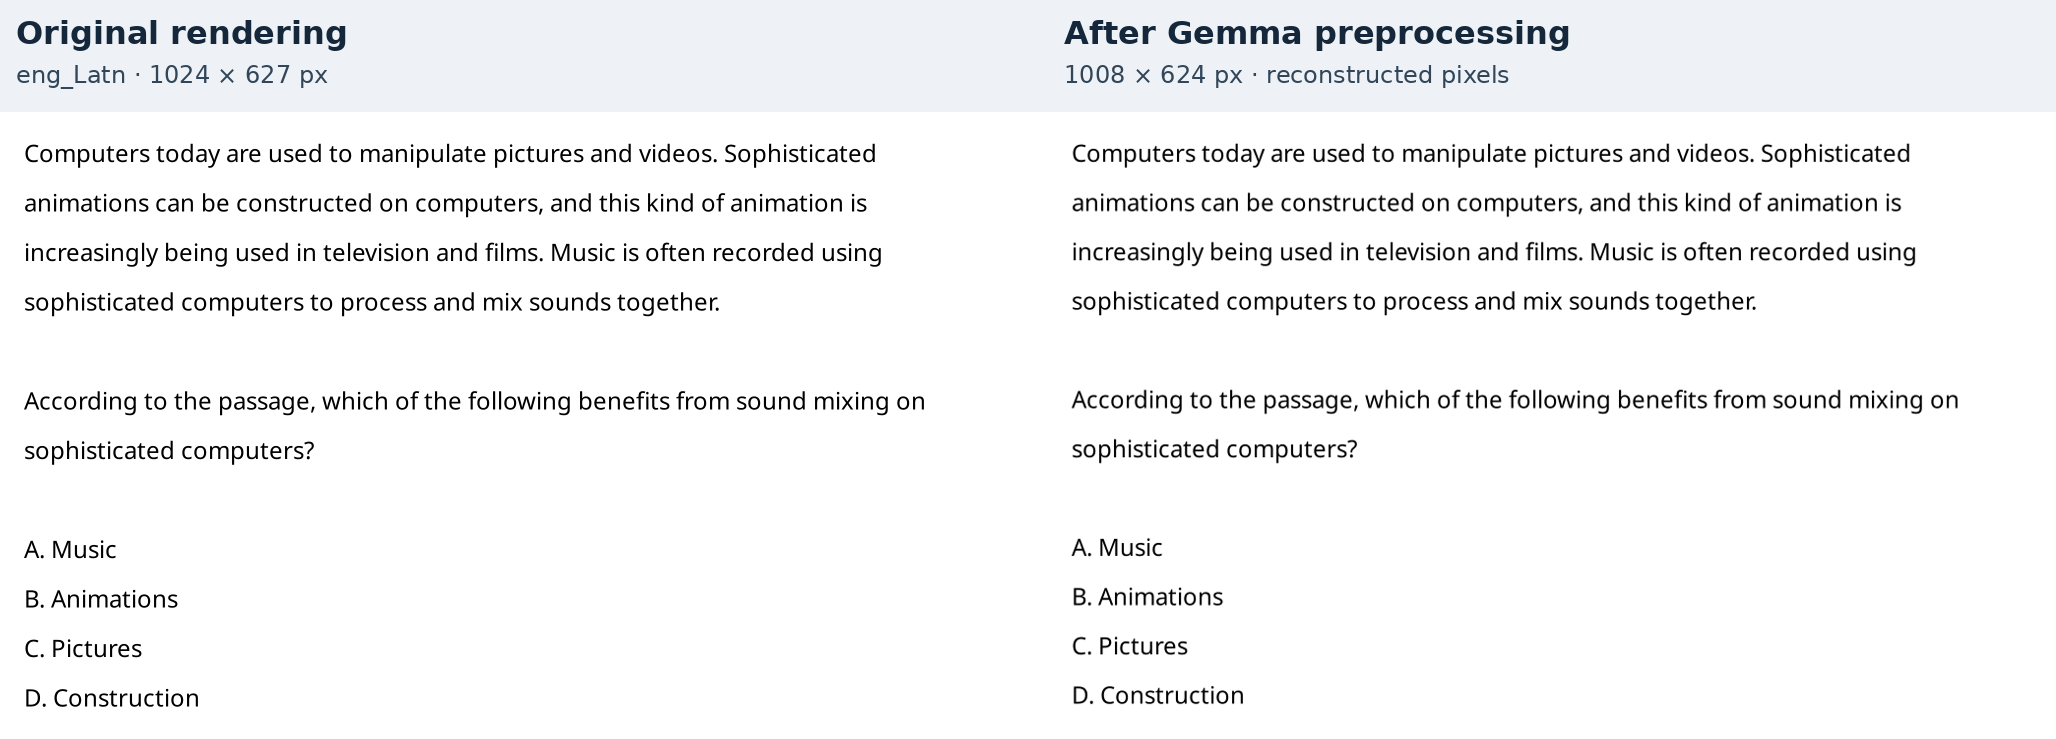

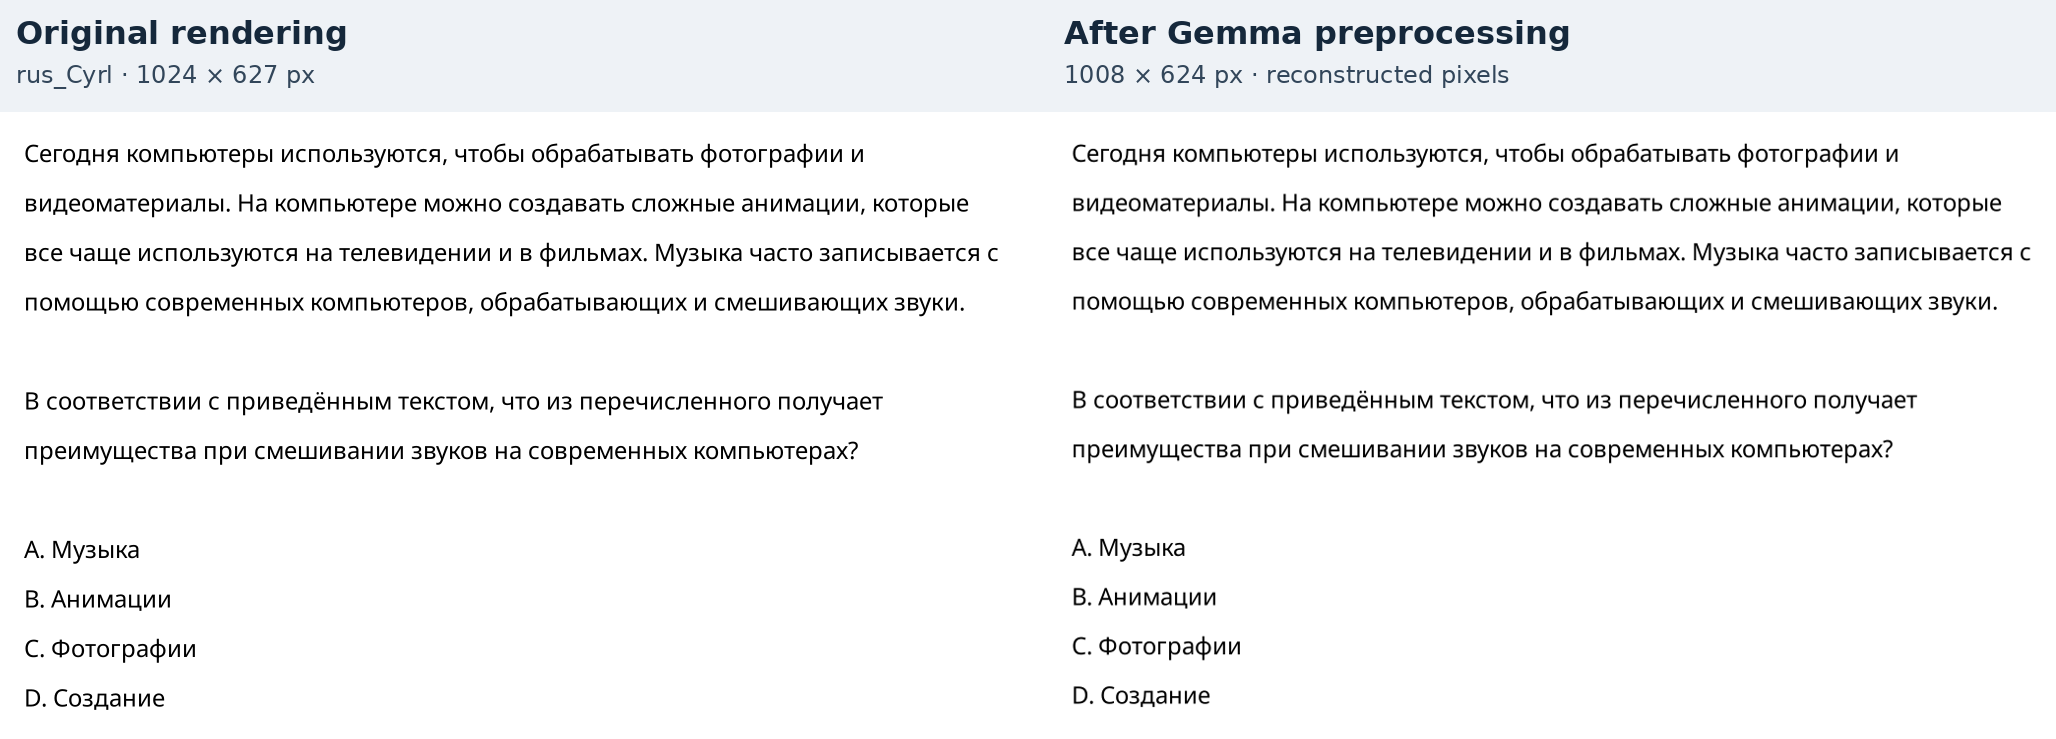

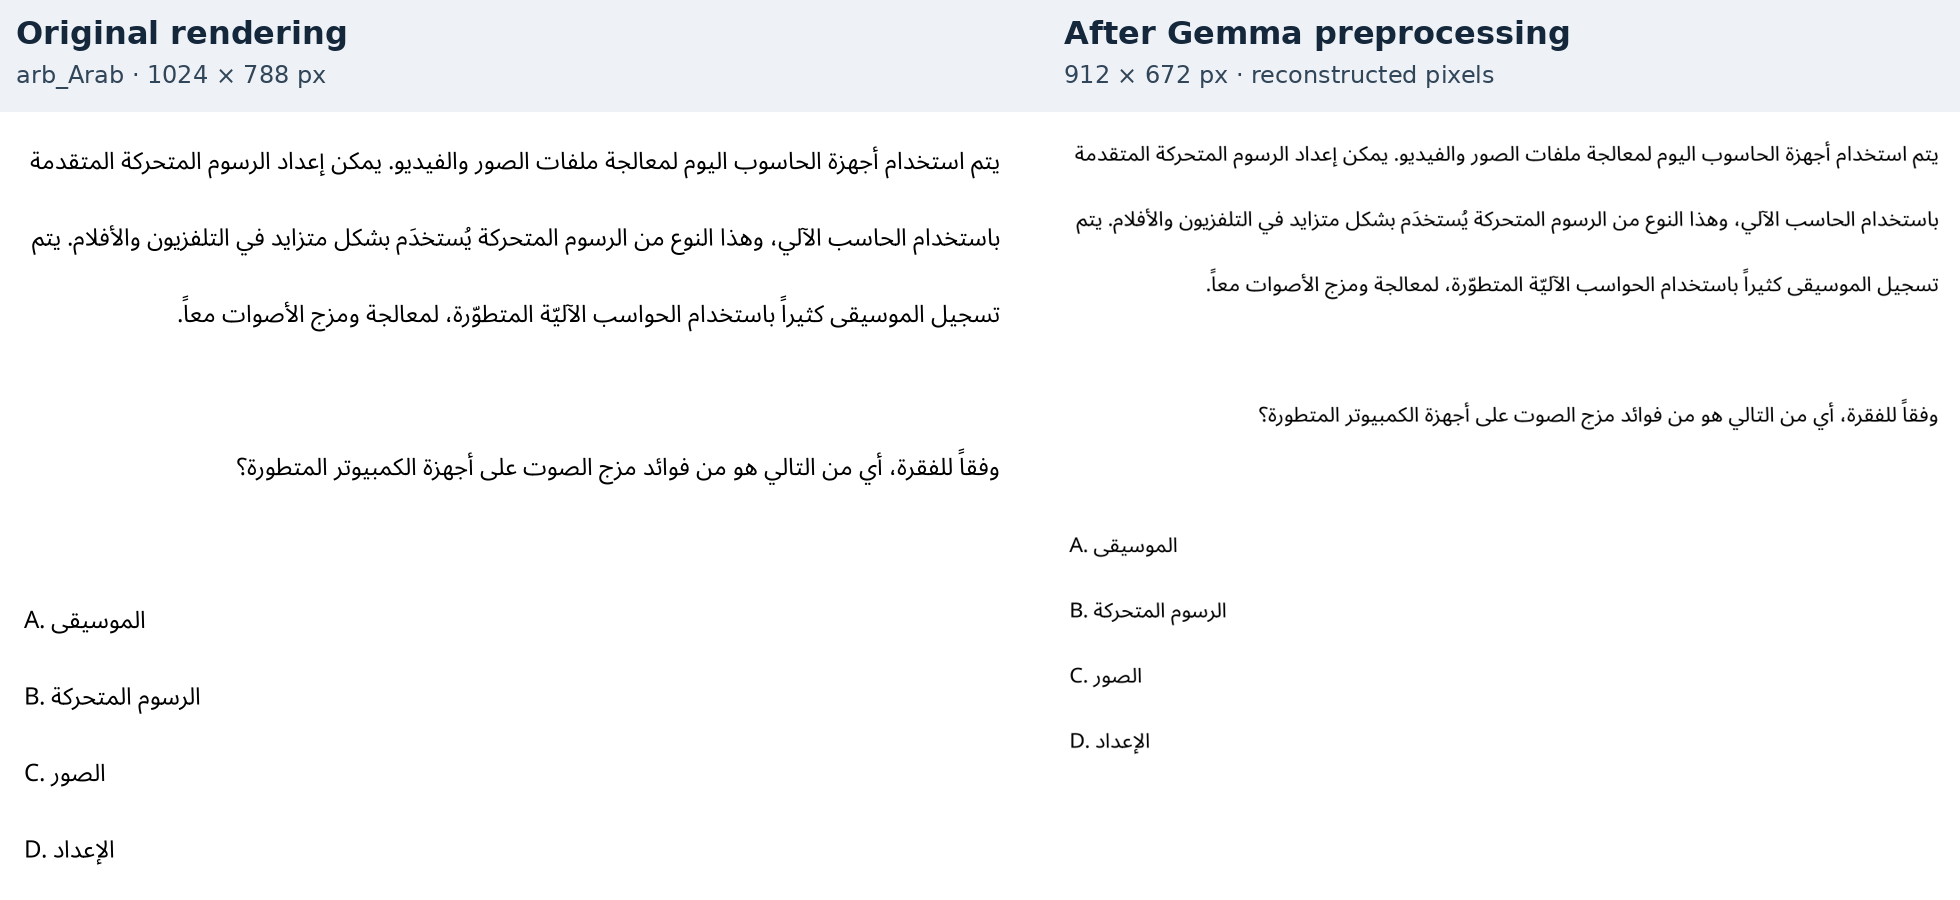

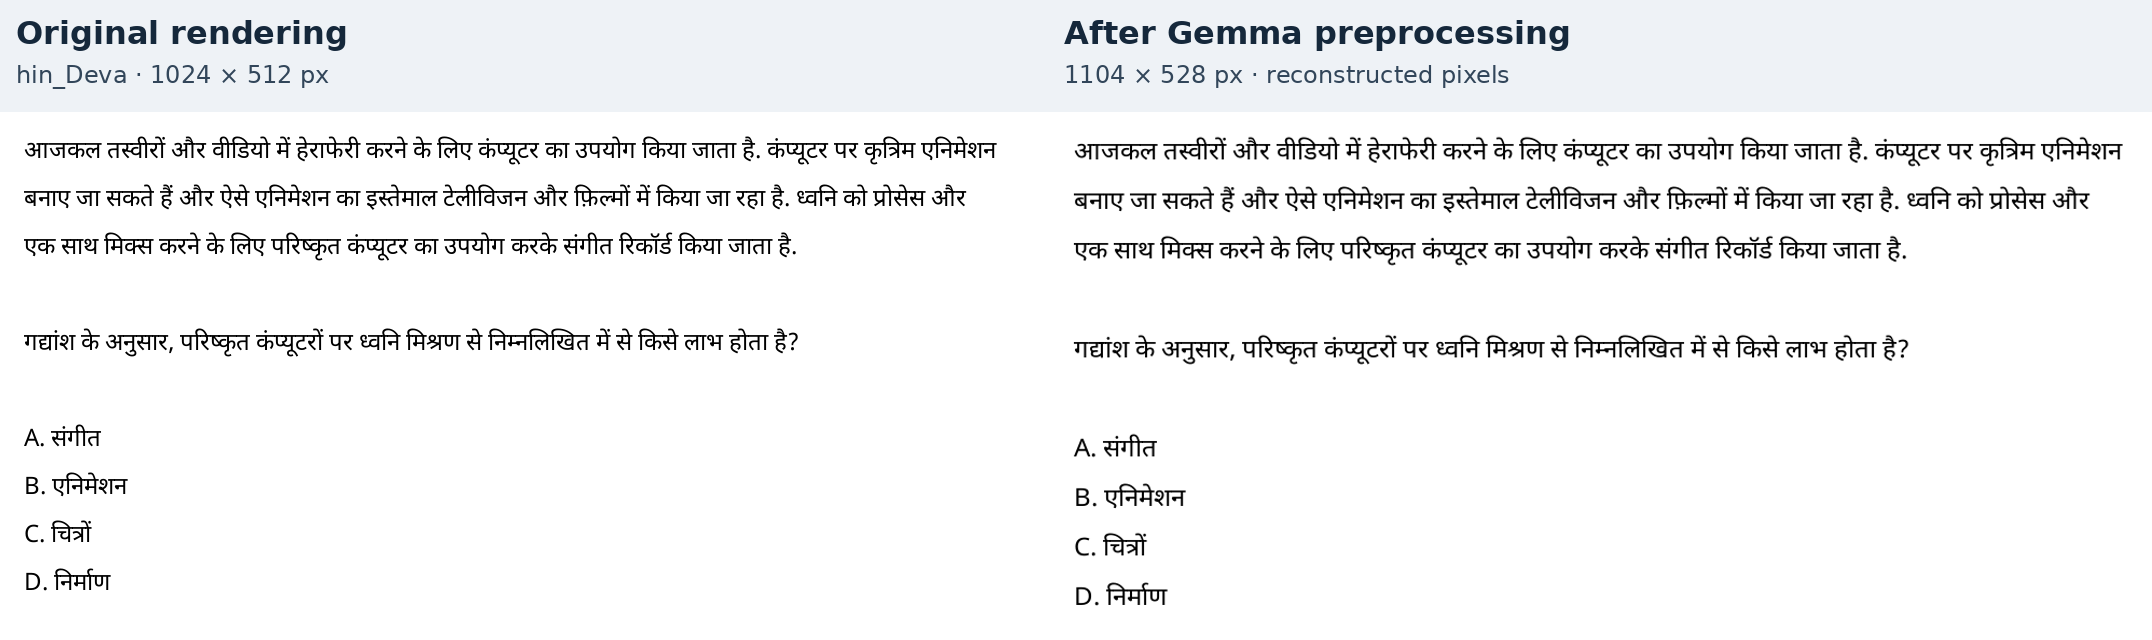

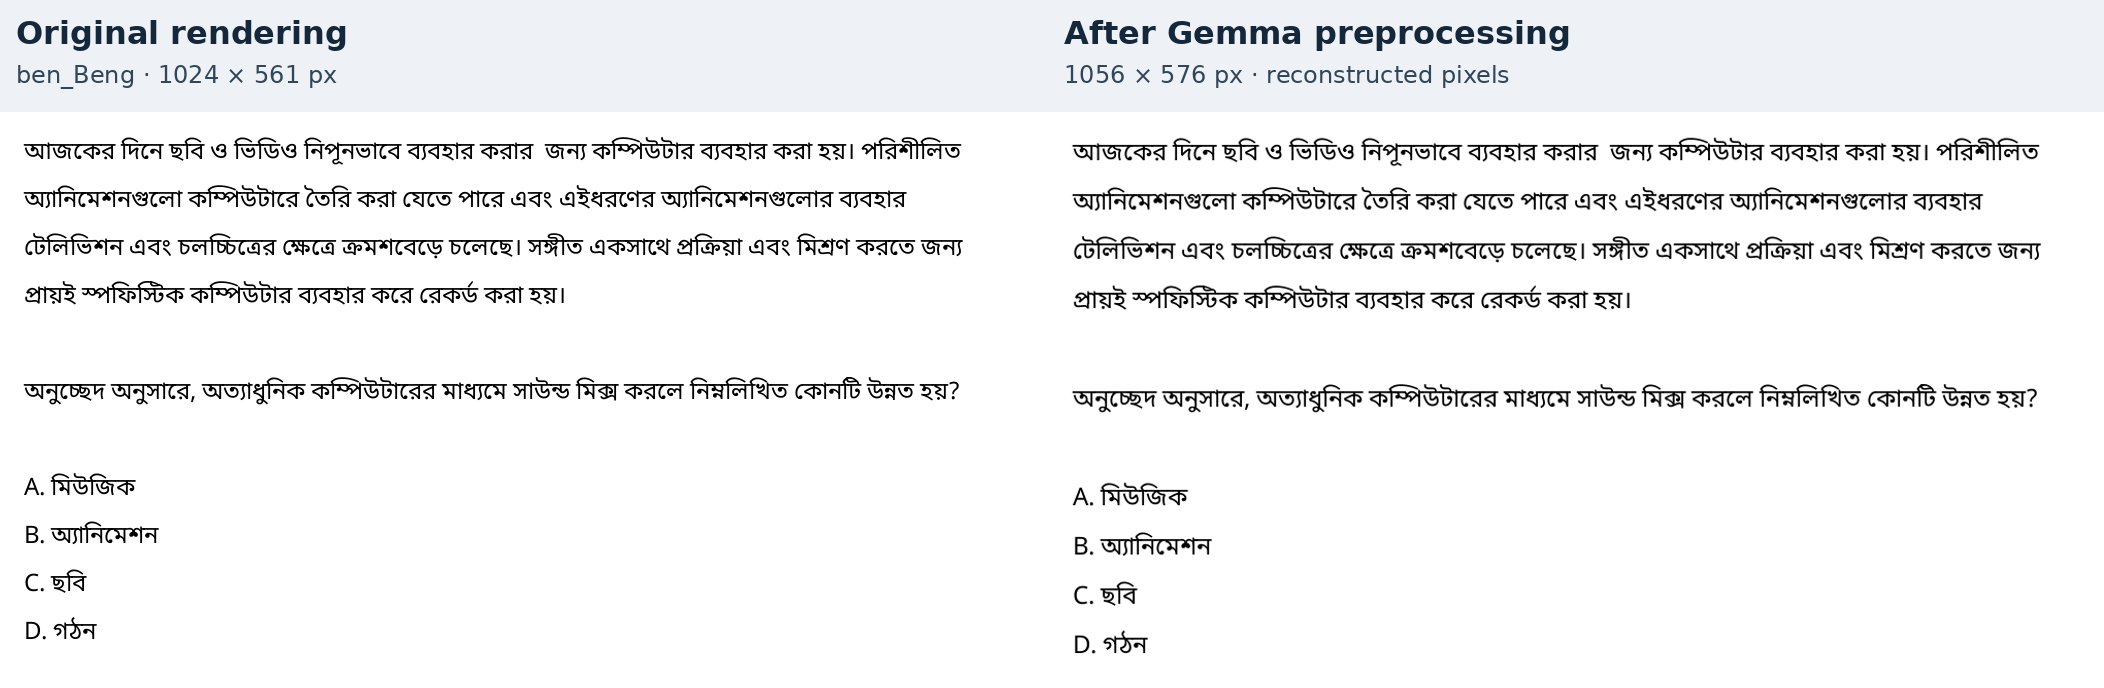

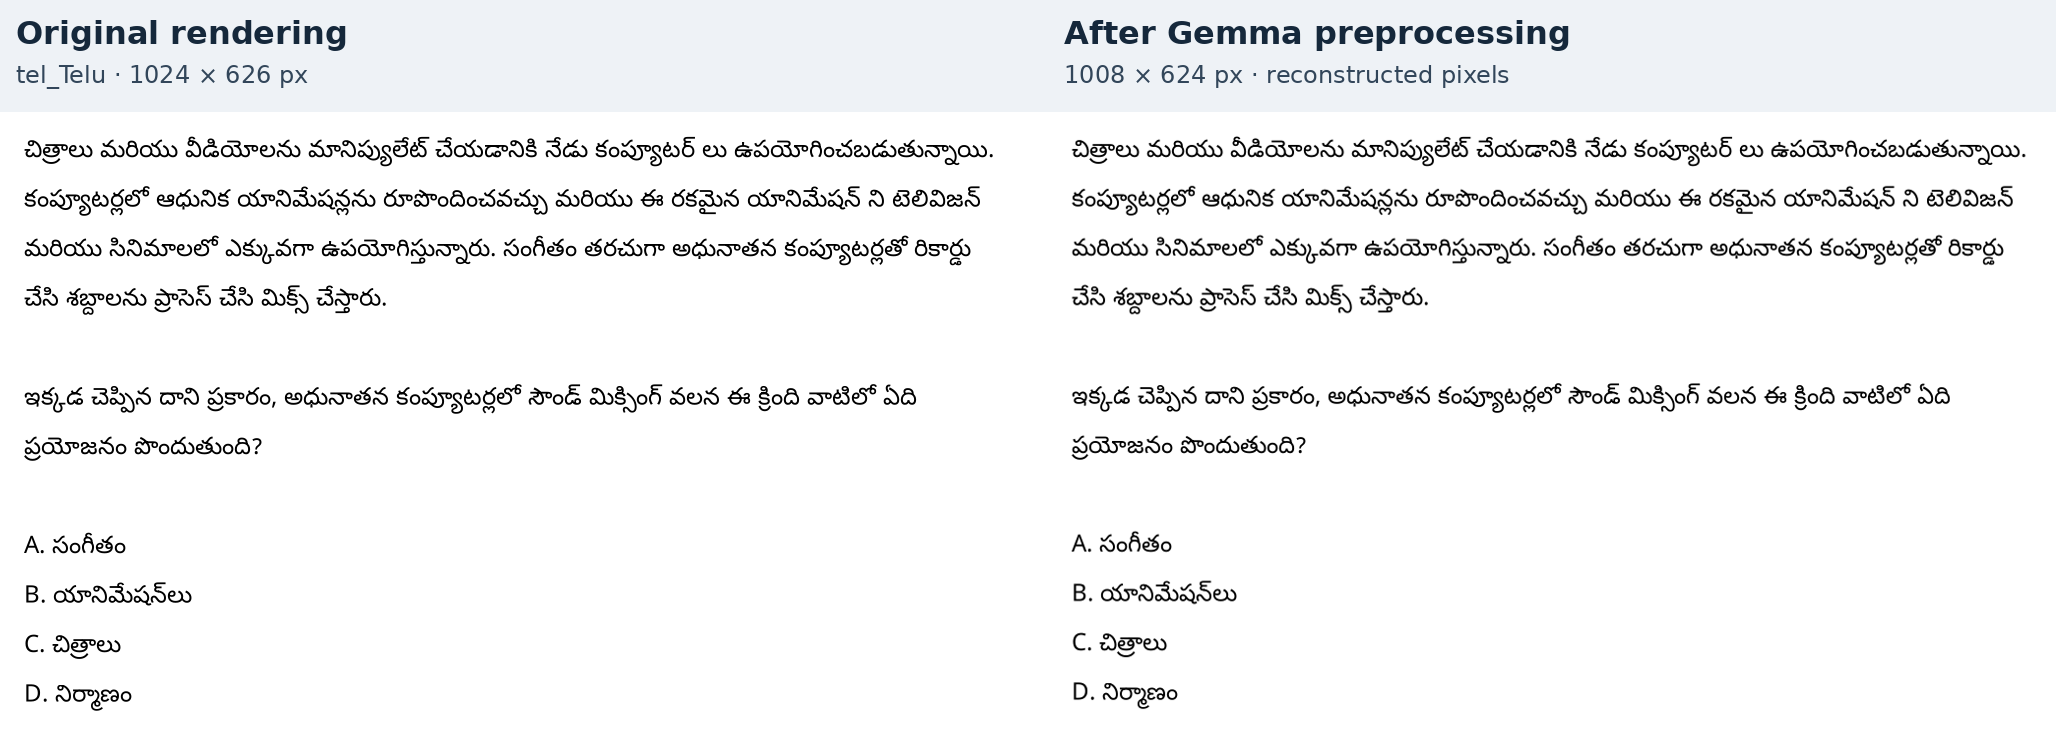

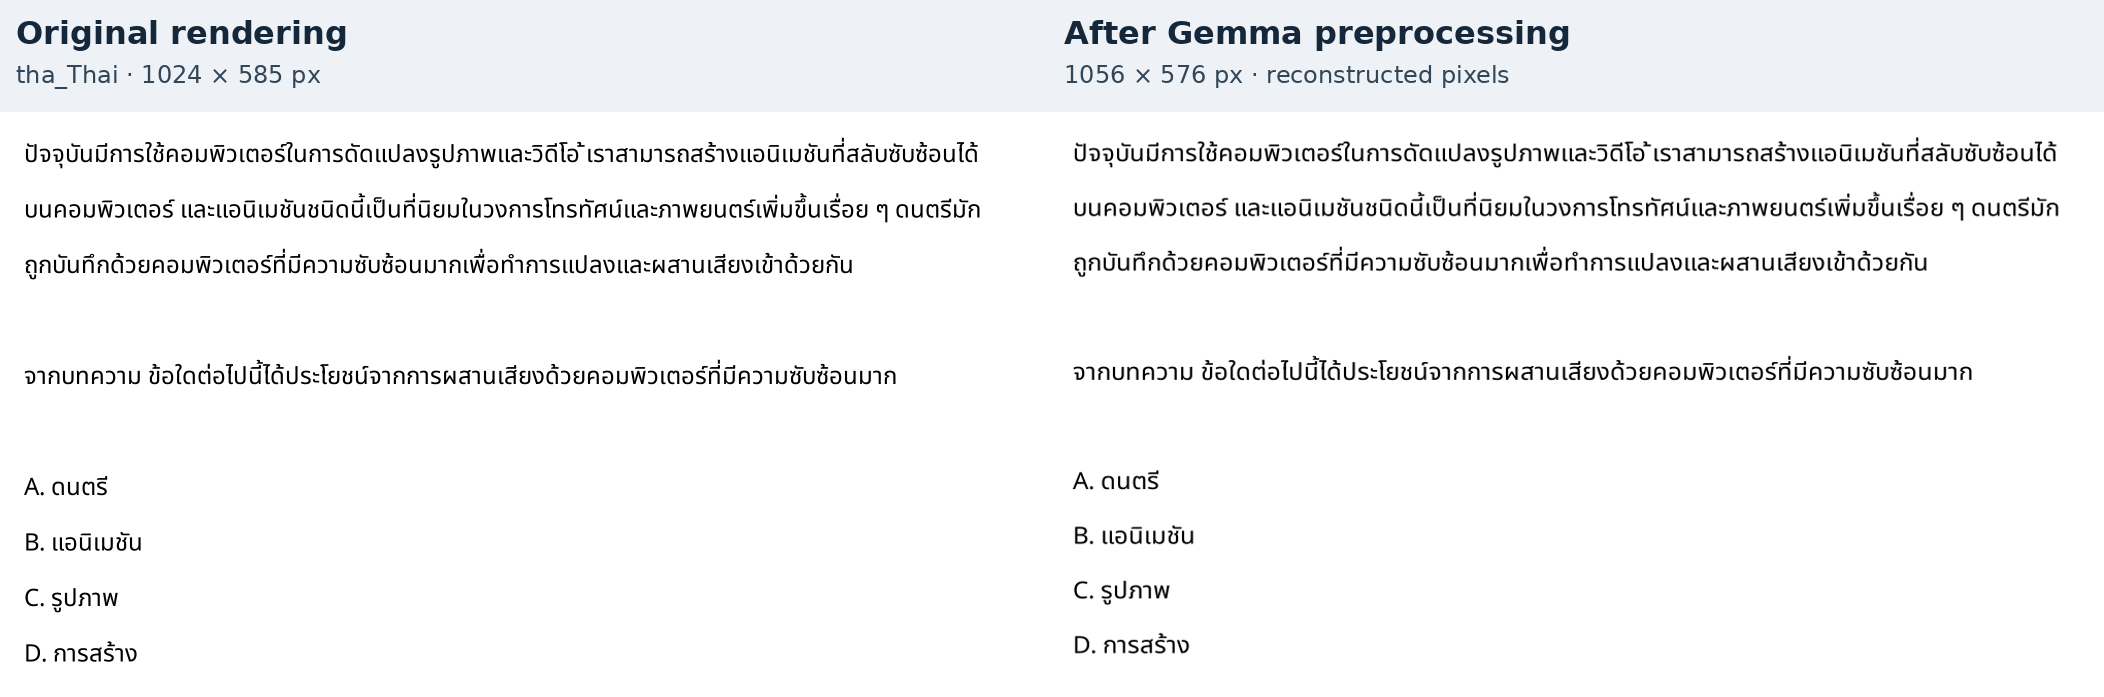

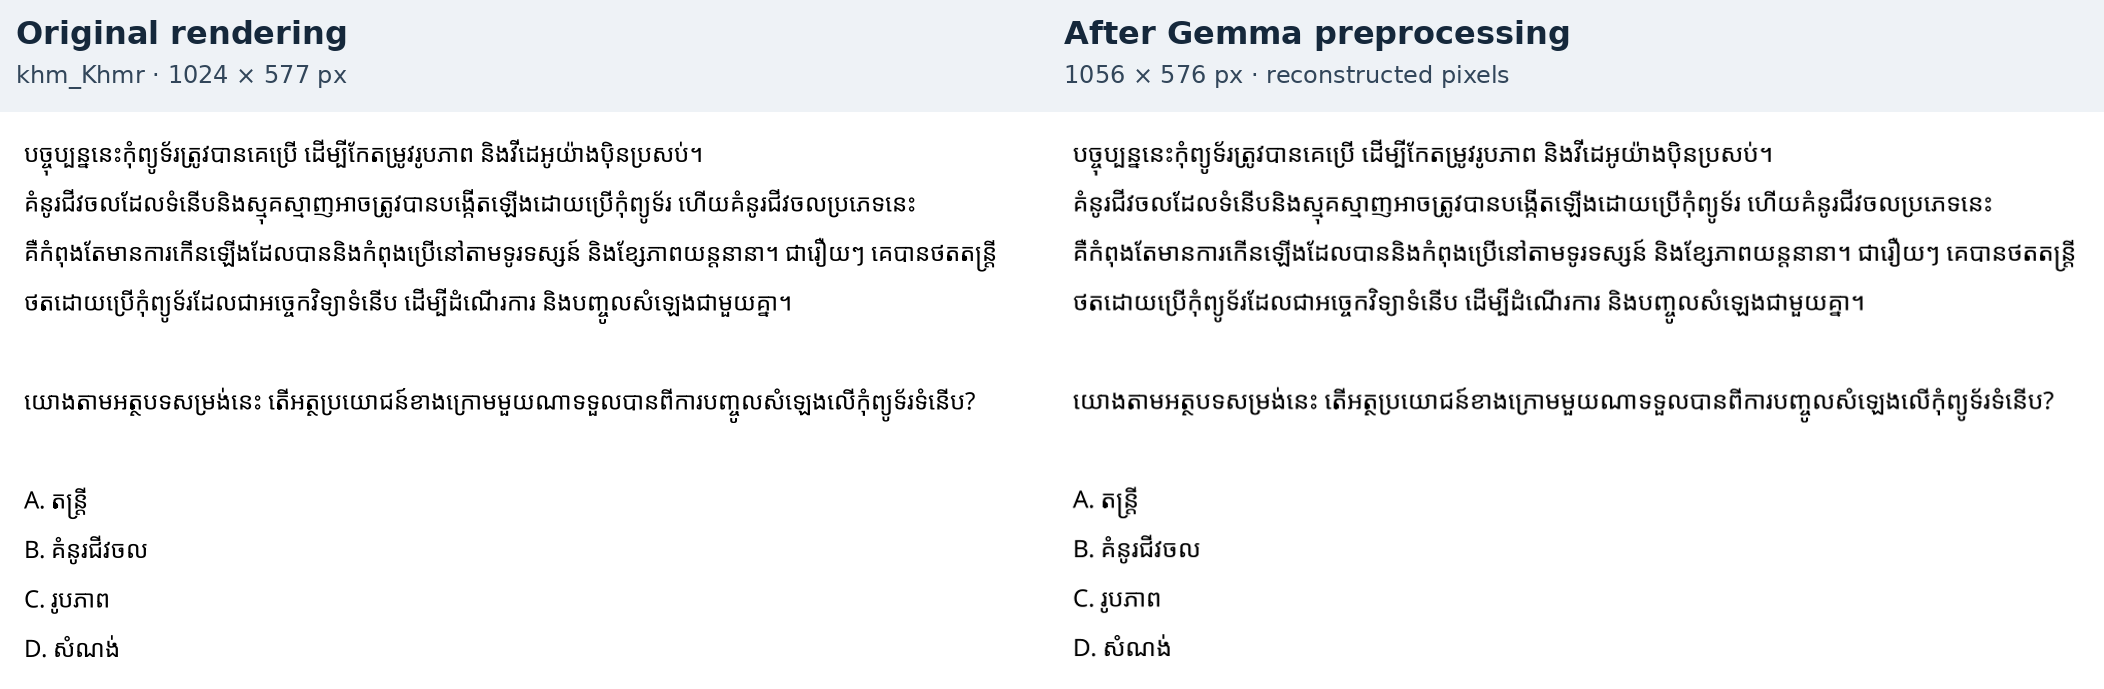

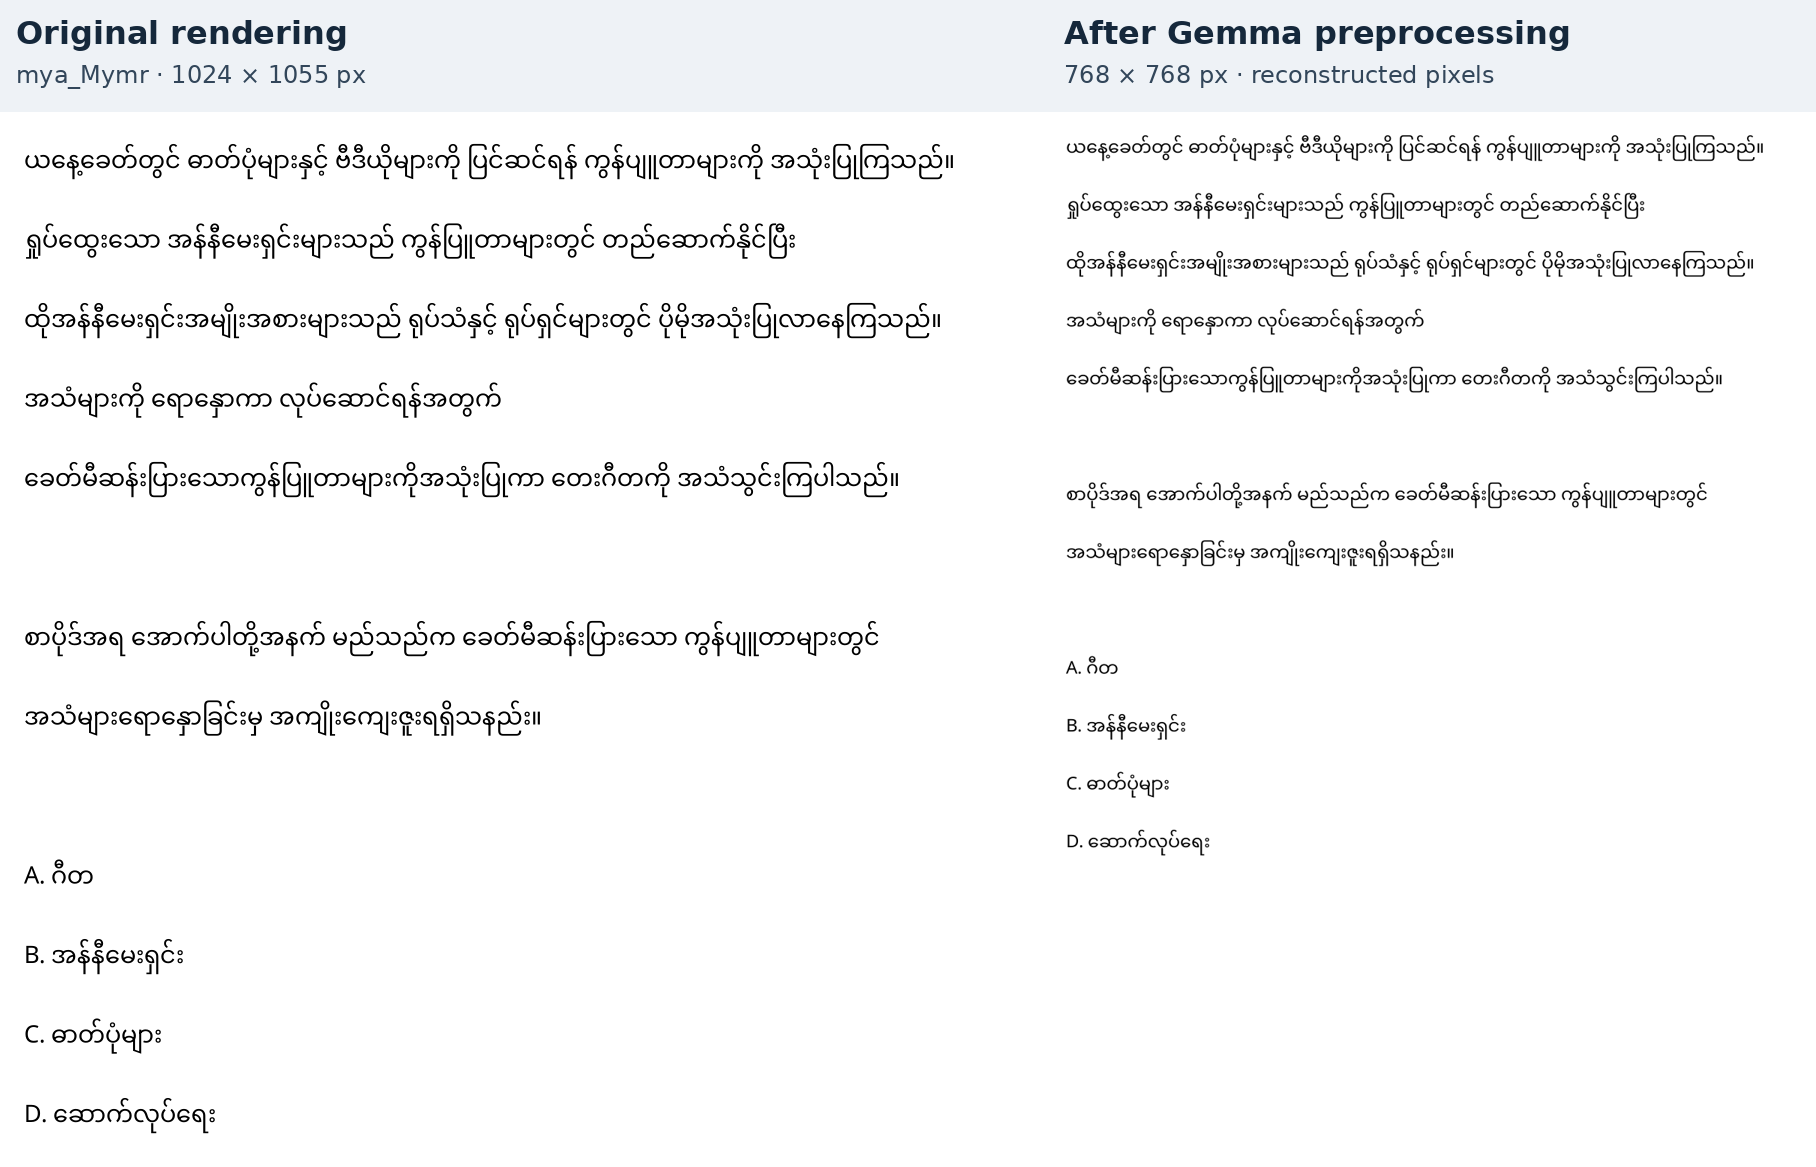

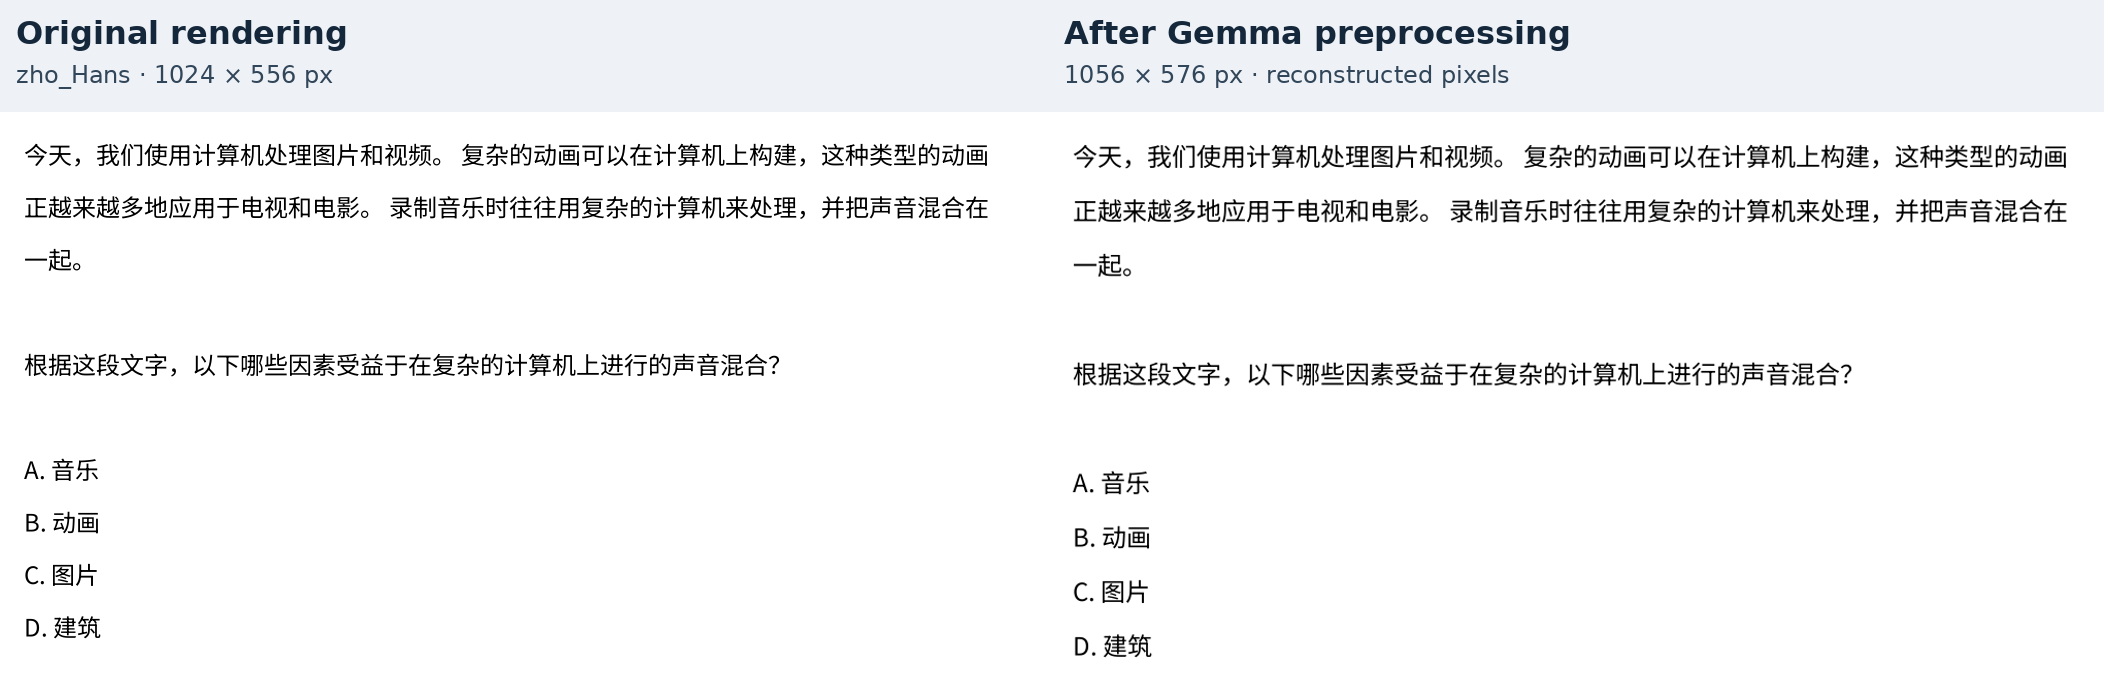

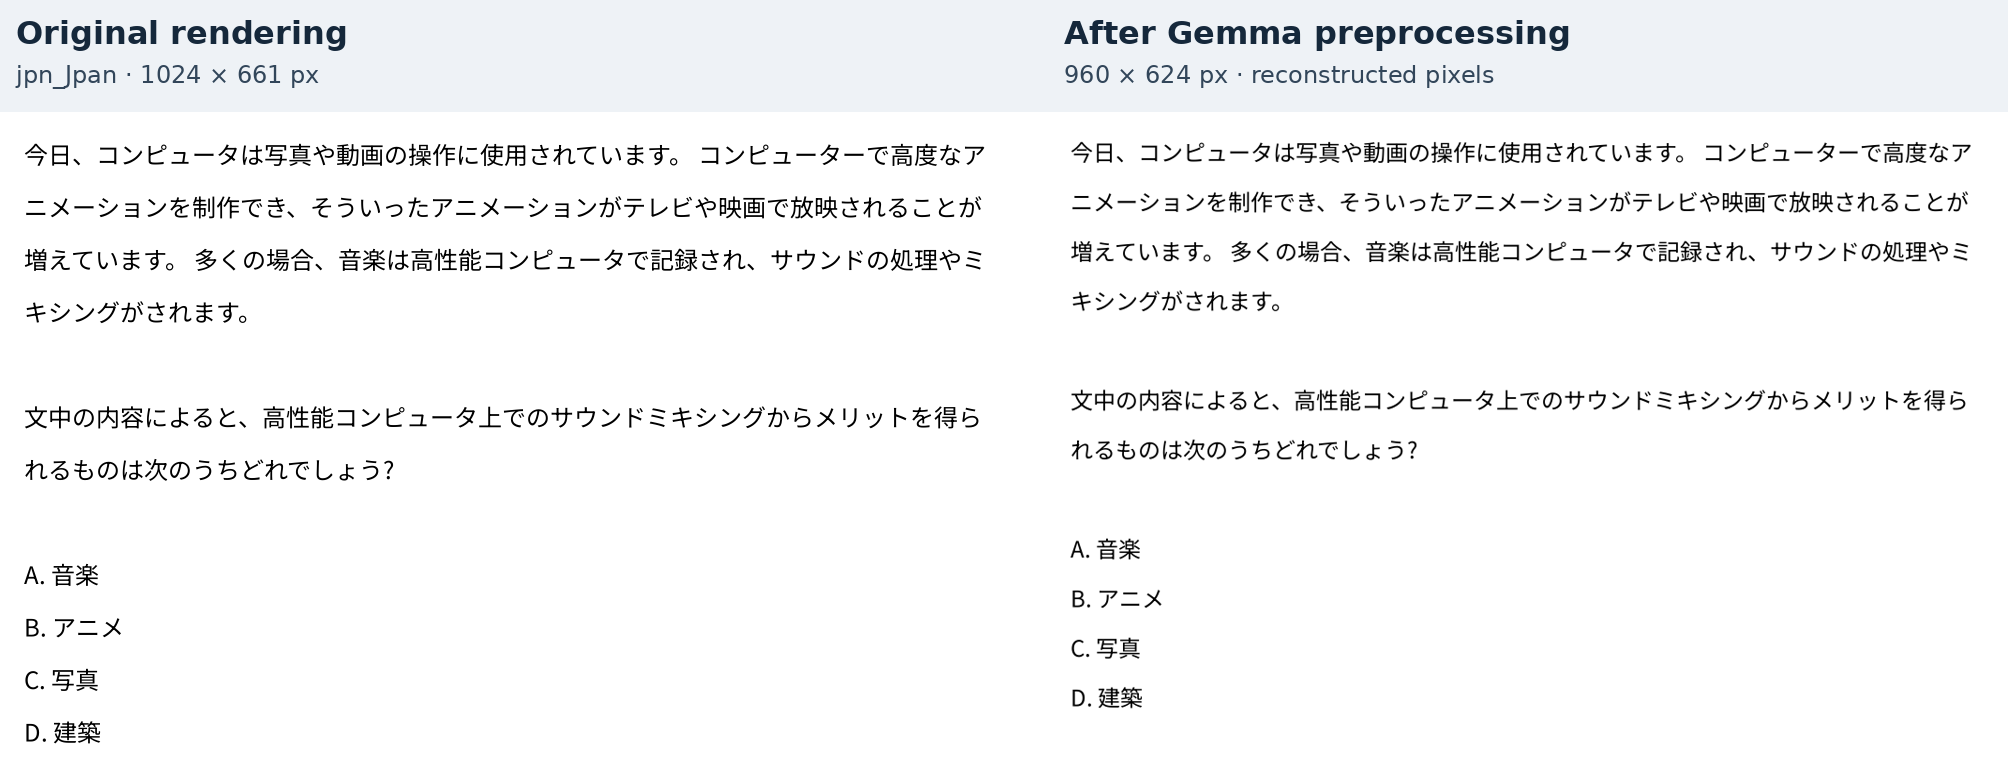

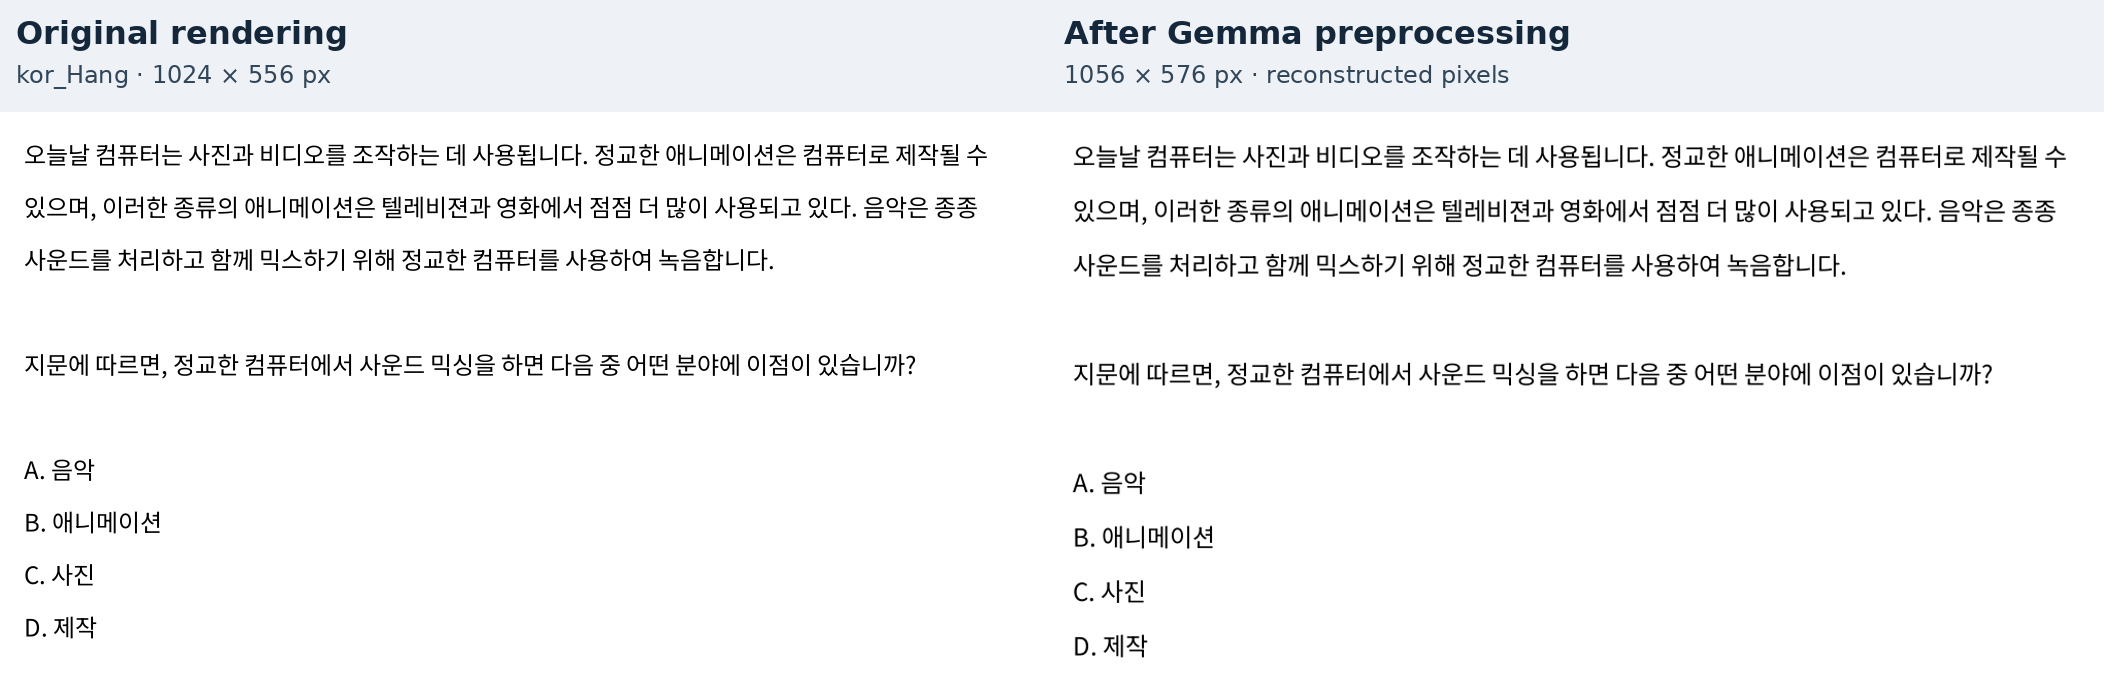

,language,sample_id,width,height,font_size,actual_fonts,unknown_glyphs,ink_bounds,processed_width,processed_height,real_patches,padded_patches,soft_tokens
0,eng_Latn,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,627,24,[Noto Sans],0,"[24, 31, 900, 565]",1008,624,2457,63,273
1,rus_Cyrl,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,627,24,[Noto Sans],0,"[24, 31, 974, 568]",1008,624,2457,63,273
2,arb_Arab,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,788,24,[Noto Sans Arabic],0,"[24, 33, 977, 721]",912,672,2394,126,266
3,hin_Deva,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,512,24,[Noto Sans Devanagari],0,"[24, 24, 973, 455]",1104,528,2277,243,253
4,ben_Beng,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,561,24,[Noto Sans Bengali],0,"[23, 25, 940, 503]",1056,576,2376,144,264
5,tel_Telu,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,626,24,[Noto Sans Telugu],0,"[24, 24, 969, 576]",1008,624,2457,63,273
6,tha_Thai,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,585,24,[Noto Sans Thai],0,"[24, 25, 956, 526]",1056,576,2376,144,264
7,khm_Khmr,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,577,24,[Noto Sans Khmer],0,"[24, 27, 972, 519]",1056,576,2376,144,264
8,mya_Mymr,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,1055,24,[Noto Sans Myanmar],0,"[24, 31, 929, 991]",768,768,2304,216,256
9,zho_Hans,5cb0570326d2c8d8f7f7655336d7a4ff9ee257392e6928...,1024,556,24,[Noto Sans SC],0,"[24, 31, 964, 496]",1056,576,2376,144,264


In [3]:
from IPython.display import display
import pandas as pd
from rendering_eval.backends import load_processor
from rendering_eval.preview import preview_example, clear_previews

processor = load_processor(config) if config.backend == "local" else None
if "image_handles" in globals():
    clear_previews(image_handles)
image_handles = []
PREVIEW_LANGUAGES = config.languages
PREVIEW_ID_INDEX = 1
preview_metadata = []
for language in PREVIEW_LANGUAGES:
    example = next(e for e in examples if e.language == language and e.sample_id == selected_ids[PREVIEW_ID_INDEX])
    handle, metadata = preview_example(config, example, renderer=renderer, processor=processor)
    image_handles.append(handle)
    preview_metadata.append(metadata)
display(pd.DataFrame(preview_metadata))


## Optional smoke inference
Set `RUN_EVALUATION=True` to run or resume this configuration. Local inference loads prequantized 4-bit NF4 weights directly, with no BF16 source conversion. It uses batch size 1, thinking disabled, and greedy decoding, and releases the model after the run. The compute dtype and actual memory use are recorded. OpenRouter reads `OPENROUTER_API_KEY` from the environment; no key is stored in the notebook or results.

Full local evaluation (900 IDs across the selected 12 languages, **21,600 predictions**):

```bash
.venv/bin/rendering-eval run --config configs/full.yaml
```

Full Qwen evaluation via OpenRouter (paid, explicit launch):

```bash
.venv/bin/rendering-eval run --config configs/openrouter-full.yaml
```


In [4]:
from rendering_eval.runner import run

# Show counts only, once per 100 completions; raw responses stay in predictions.jsonl.
def report_progress(message):
    counts = message.split(" ", 1)[0].split("/")
    if len(counts) == 2 and all(part.isdigit() for part in counts):
        completed, total = map(int, counts)
        if completed % 100 == 0 or completed == total:
            print(f"{completed}/{total} predictions completed", flush=True)
    else:
        print(message, flush=True)

if RUN_EVALUATION:
    predictions = run(config, examples=examples, renderer=renderer, progress=report_progress)
else:
    print("Inference disabled. Set RUN_EVALUATION=True for the configured evaluation.")


Inference disabled. Set RUN_EVALUATION=True for the configured evaluation.


## Paired results
Accuracy is calculated on completed text/image pairs. Invalid or truncated model responses count as incorrect. Execution errors remain pending. Two IDs are for plumbing and readability checks, not language rankings. Modality differences include rendering, image preprocessing, and reasoning; they do not isolate OCR or causal script effects.


In [5]:
from rendering_eval.analysis import analyze, plot_summary
import matplotlib.pyplot as plt
summary = analyze(config.output_dir)
print(summary["status"], f"{summary['completed_predictions']}/{summary['expected_predictions']} predictions")
display(pd.DataFrame(summary["groups"]))
figure = plot_summary(summary)
if figure is not None:
    image_handles.append(display(figure, display_id=True))
    plt.close(figure)


pending 0/48 predictions


,language,completed_predictions,paired_examples,text_accuracy,image_accuracy,image_minus_text_pp,both_correct,text_only_correct,image_only_correct,both_wrong,invalid_responses,truncated_responses
0,ALL,0,0,None,None,None,0,0,0,0,0,0
1,eng_Latn,0,0,None,None,None,0,0,0,0,0,0
2,rus_Cyrl,0,0,None,None,None,0,0,0,0,0,0
3,arb_Arab,0,0,None,None,None,0,0,0,0,0,0
4,hin_Deva,0,0,None,None,None,0,0,0,0,0,0
5,ben_Beng,0,0,None,None,None,0,0,0,0,0,0
6,tel_Telu,0,0,None,None,None,0,0,0,0,0,0
7,tha_Thai,0,0,None,None,None,0,0,0,0,0,0
8,khm_Khmr,0,0,None,None,None,0,0,0,0,0,0
9,mya_Mymr,0,0,None,None,None,0,0,0,0,0,0


No completed text/image pairs yet; accuracy is pending.


## Clear images before saving
Run the next cell before saving. For a guaranteed clean saved notebook, use `python scripts/clean_notebook.py Belebele.ipynb`. Notebook frontends may embed live displays during autosave, so disable autosave while inspecting if you need to avoid that.

[Belebele](https://huggingface.co/datasets/facebook/belebele), CC BY-SA 4.0; [sign/pixel-renderer](https://github.com/sign/pixel-renderer), MIT; [Noto fonts](https://github.com/google/fonts), SIL OFL. See README for setup, provenance, API routing, and attribution.


In [6]:
# clear_previews(image_handles)
# plt.close("all")
# print("Image displays cleared. JSON results remain available.")
